# 6.2 - Features: what a model could learn from, each tested on its own

Notebook 6.1 set the rules and found the ground firmest at a monthly horizon, where a typical move pays for many round
trips of trading costs. This notebook builds the **features** - the inputs a model will learn from - for every
S&P 1500 member at every month end from 2005 to 2024, and tests each one *alone* before any model combines them.

Testing first matters for two reasons. A model given 50 features will find patterns in some of them by chance, so
it helps to know beforehand which features carry information on their own. And features that rank companies the
same way add nothing to each other, so it helps to know which are near-duplicates - of each other, of the factors
this repository already has, or of the risk model's styles.

The features come in seven families: momentum and reversal, risk, liquidity, accounts, model-based volatility and
trend, a market regime, and the calendar. Each is defined below with the research it comes from (modules
`features.py` and `model_features.py`).

## The features

Every feature is known at the close of its month end: prices up to that day, accounts as published by then, model
parameters fitted only on earlier years. Days are trading days ("1m" = 21 days, "3m" = 63, "1y" = 252).

| Family | Feature | Definition | Why it might predict |
|---|---|---|---|
| Momentum | `mom_12_1`, `mom_6_1` | return from 12 (6) months to 1 month ago | winners keep winning for months (Jegadeesh and Titman, 1993) |
| | `resid_mom` | the last year's monthly returns less the market's share, per unit of their own noise | momentum without the beta bet (Blitz, Huij and Martens, 2011) |
| Reversal | `ret_1m`, `ret_1w` | the last month's (week's) return | short-term winners give some back (Jegadeesh, 1990; Lehmann, 1990) |
| Risk | `vol_1m`, `vol_1y` | annualised volatility of daily returns | calm shares have done as well as volatile ones, or better (Ang et al., 2006) |
| | `idio_vol_3m` | volatility of the part of returns the market does not explain | the "idiosyncratic volatility puzzle" (Ang et al., 2006) |
| | `beta_1y` | sensitivity to the market | low-beta shares have earned more than the CAPM predicts (Frazzini and Pedersen, 2014) |
| | `max_ret_1m` | the largest daily return in a month | lottery-like shares are overpriced (Bali, Cakici and Whitelaw, 2011) |
| | `skew_1y` | skewness of daily returns | investors overpay for positive skew |
| Liquidity | `dollar_volume_1m` | average daily traded value | illiquid shares earn a premium (Amihud, 2002) |
| | `turnover_1m` | traded value over market value | |
| | `amihud_1m` | average of absolute return per million traded: the price impact of trading | |
| | `zero_days_3m` | share of days with no price change (Lesmond et al., 1999) | |
| | `roll_spread_3m` | Roll's (1984) bid-ask spread from consecutive returns | |
| Accounts | 18 ratios | the ratios of *Build Your Own AI Investor* (notebooks 5.1-5.3): valuation, returns, margins, leverage, liquidity, Altman's four | |
| | `size` | market value | small companies behave differently (Banz, 1981) |
| | `share_change` | change in shares outstanding over a year | issuers lag, buyers back lead (Pontiff and Woodgate, 2008) |
| | `earnings_surprise` | the latest quarter's standardised surprise | prices drift after earnings news (Bernard and Thomas, 1989) |
| | `eps_growth`, `sales_growth` | growth of trailing earnings and sales per share | |
| Model-based | `garch_vol` | GARCH(1,1) forecast of tomorrow's volatility, refitted each January on three years | volatility that reacts to shocks and decays (Bollerslev, 1986) |
| | `har_vol` | HAR forecast of next month's volatility from the last day, week and month (Corsi, 2009) | |
| | `ffd_price` | the log price fractionally differenced ($d$ = 0.4): memory kept, trend mostly removed (Lopez de Prado, 2018) | |
| | `trend_slope`, `trend_gap` | a Kalman (Holt) filter's trend of the log price, and the price's gap from the filtered level | |
| | `break_stat` | the largest standardised move over the last 5 to 63 days: how unusual the latest run is | |
| Market | `turbulent` | probability the market is in its turbulent state, from a two-state switching model refitted each January (Hamilton, 1989) | the same for every company |
| Calendar | `month_sin`, `month_cos`, `january` | the month as a point on a circle; January | the same for every company |

Our price bars have no daily high and low, so the high-low spread estimators the book uses (Corwin and Schultz,
2012) cannot be computed; Roll's estimate needs closes only.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.research import evaluation as ev
from equity_research.research import features as ft
from equity_research.research import labels as lb
from equity_research.research import model_features as mf
from equity_research.research import risk_model as rm
from equity_research.research import store
from equity_research.research.cache import ResearchCache
from equity_research.research.data import load_universe_data
from equity_research.research.risk_data import load_risk_inputs
from equity_research.research.risk_styles import substyles
from equity_research.research.strategy import factor_scores

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
charts.style()

UNIVERSE, START, END = "SP1500", "2005-01-01", "2024-12-31"  # END: the last day before the hold-out
FDR = 0.10  # Benjamini-Hochberg false-discovery rate for the triage
cache = ResearchCache()
SNAPSHOT = store.data_snapshot(cache)
data = load_universe_data(cache, UNIVERSE, START, END)
dates = data.rebalances
print(f"{data.returns.shape[1]:,} listings, {len(dates)} month ends, data snapshot {SNAPSHOT}")

left out 887 facts of 2 companies in ['GBP']


3,159 listings, 240 month ends, data snapshot 2026-11-14T16:44:34


## Step 1 - building the features

The company features are built once per data version and kept in the artifact store (the first build is the slow
one, mostly the GARCH fits: one per member per year). The market regime and the calendar are the same for every
company on a date, so they are kept apart.

In [2]:
def build() -> pd.DataFrame:
    """Every company feature on the month ends, members only."""
    dollars = ft.dollar_volume(cache, data)
    log_price = np.log(data.adjusted.where(data.adjusted > 0))
    slope, gap = mf.kalman_trend(log_price)
    model = {
        "garch_vol": mf.garch_volatility(data.returns, data.members, dates),
        "har_vol": mf.har_volatility(data.returns, data.members, dates),
        "ffd_price": mf.frac_diff(log_price, d=0.4).reindex(dates),
        "trend_slope": slope.reindex(dates),
        "trend_gap": gap.reindex(dates),
        "break_stat": mf.break_statistic(data.returns).reindex(dates),
    }
    panels = ft.price_features(data, dollars, dates) | ft.fundamental_features(data, dates) | model
    return ft.stack(panels, data.members)


CONFIG = {"universe": UNIVERSE, "start": START, "end": END, "dates": "month ends", "version": 1}
long = store.cached("features", "company_month_end", CONFIG, build, snapshot=SNAPSHOT)
panels = ft.unstack(long)
market = ft.market_return(data)
date_level = ft.calendar_features(dates).assign(turbulent=mf.market_regime(market, dates))
print(
    f"{len(panels)} company features on {long.index.get_level_values('date').nunique()} month ends, "
    f"{len(long):,} member-months; {date_level.shape[1]} date features"
)

45 company features on 240 month ends, 360,228 member-months; 5 date features


How much of the index each feature covers: the share of member-months with a value, by period. Features that need
history start late: momentum and the year-long risk measures need a year of prices, the GARCH and HAR forecasts a year
of returns before their first fit.

In [3]:
by_period = (
    long.notna()
    .groupby(
        pd.cut(
            long.index.get_level_values("date").year,
            [2004, 2007, 2012, 2018, 2024],
            labels=["2005-07", "2008-12", "2013-18", "2019-24"],
        ),
        observed=True,
    )
    .mean()
    .T
)
display(by_period.style.format("{:.0%}").background_gradient(cmap="Greens", vmin=0, vmax=1, axis=None))

,2005-07,2008-12,2013-18,2019-24
mom_12_1,99%,99%,99%,99%
mom_6_1,100%,100%,100%,100%
ret_1m,100%,100%,100%,100%
ret_1w,100%,100%,100%,100%
resid_mom,69%,99%,99%,99%
vol_1m,100%,100%,100%,100%
vol_1y,100%,100%,100%,100%
idio_vol_3m,97%,100%,100%,100%
beta_1y,83%,100%,100%,100%
max_ret_1m,100%,100%,100%,100%


## Step 2 - the triage: which features predict next month's return on their own

Each feature's rank IC against the next month's return (the month-to-month label of notebook 6.1), every month end
2005-2024, with the inference of 6.1: the Newey-West t-statistic (no lags: monthly labels do not overlap), its
two-sided p-value, and the Benjamini-Hochberg verdict at a false-discovery rate of 10 % across *all* the features
tested here. A negative IC is as useful as a positive one - a model can learn the sign - so the verdict is on the IC's
size, not its direction.

,mean_ic,t_nw,p_value,discovery,spread,turnover,rank_autocorrelation
signal,,,,,,,
share_change,-0.0171,-3.87,0.0001,True,-0.34%,11%,0.95
ROCE,+0.0201,+2.89,0.0038,True,+0.06%,7%,0.98
idio_vol_3m,-0.0251,-2.52,0.0117,False,+0.02%,20%,0.90
RoE,+0.0162,+2.50,0.0123,False,+0.07%,7%,0.97
sales_growth,+0.0157,+2.37,0.0178,False,+0.15%,9%,0.97
Op. In./(NWC+FA),+0.0164,+2.30,0.0213,False,-0.09%,7%,0.97
zero_days_3m,-0.0077,-2.23,0.0260,False,+nan%,31%,0.73
max_ret_1m,-0.0204,-2.05,0.0402,False,-0.01%,61%,0.42
EBIT/TA,+0.0157,+2.04,0.0409,False,+0.00%,6%,0.98


2 of 45 features are discoveries at a 10% false-discovery rate


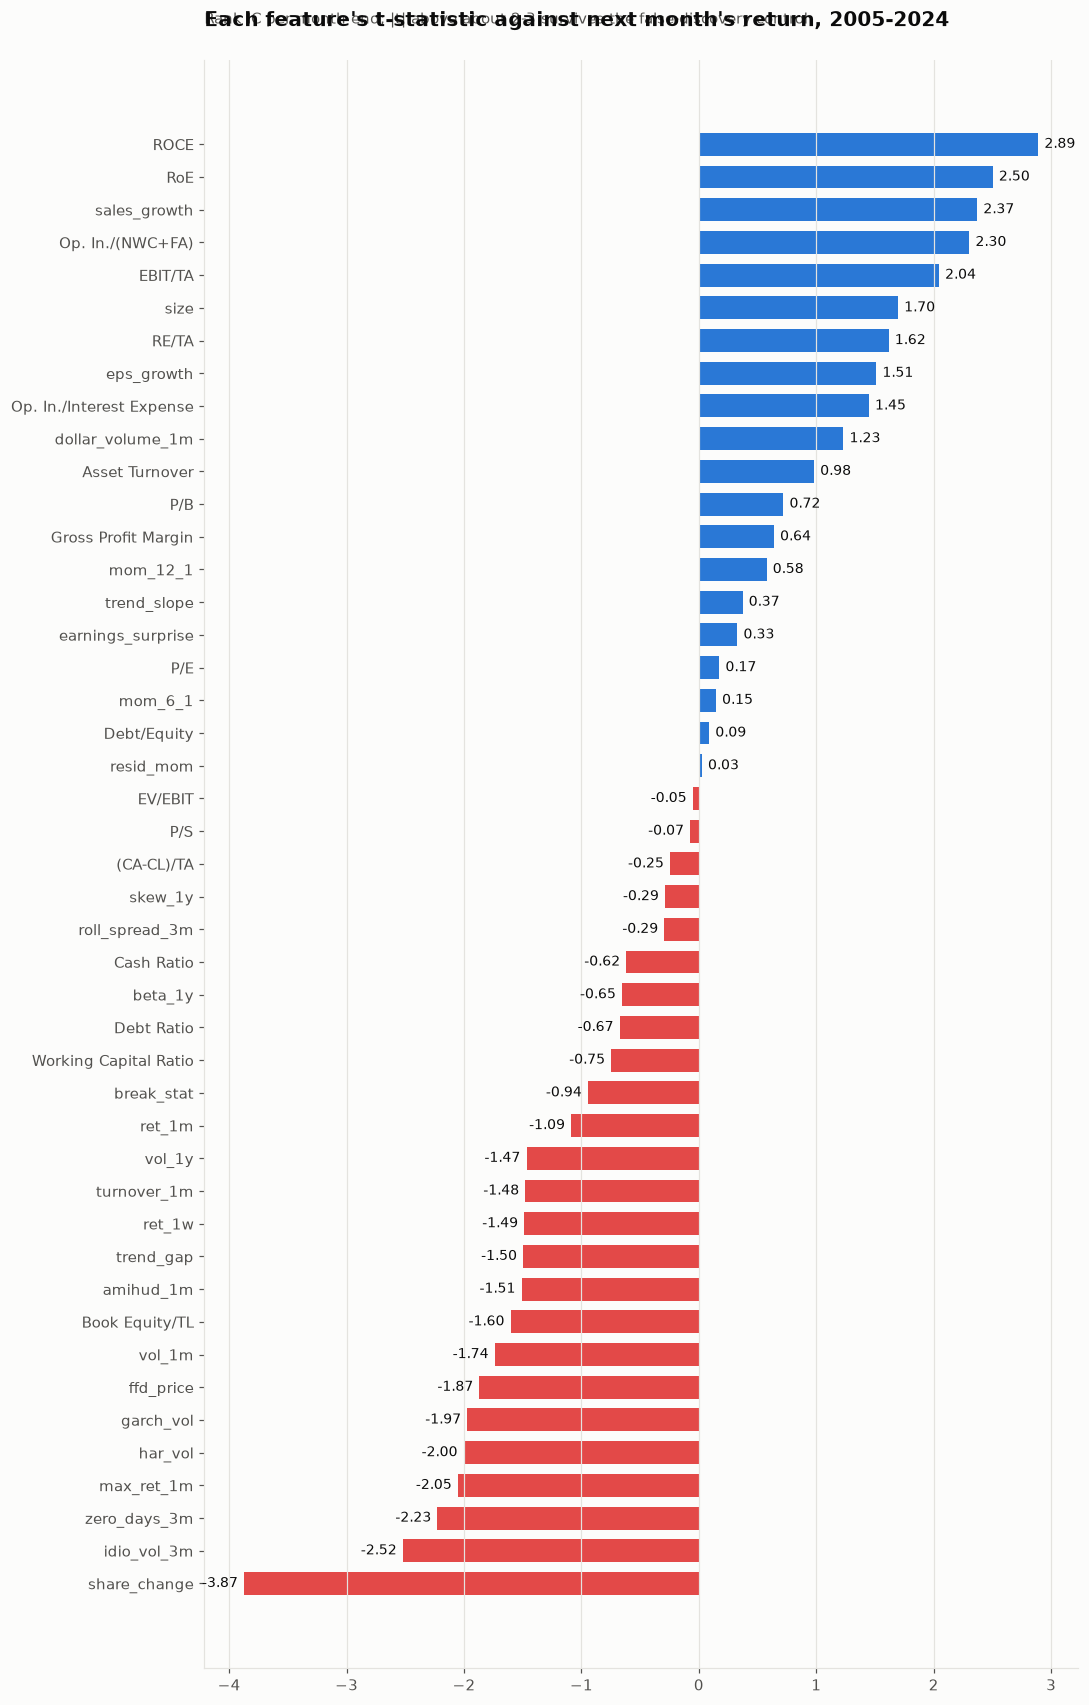

In [4]:
monthly = store.cached(
    "labels",
    "fwd_ret_month",
    {"universe": UNIVERSE, "start": START, "end": END, "dates": "rebalances"},
    lambda: lb.period_returns(data.returns, dates),
    snapshot=SNAPSHOT,
)
ledger = ev.triage(panels, monthly, data.members, lags=0, q=FDR)
store.save(
    ledger, "triage", "company_features_month", CONFIG | {"label": "fwd_ret_month", "fdr": FDR}, snapshot=SNAPSHOT
)
display(
    ledger.style.format(
        {
            "mean_ic": "{:+.4f}",
            "t_nw": "{:+.2f}",
            "p_value": "{:.4f}",
            "spread": "{:+.2%}",
            "turnover": "{:.0%}",
            "rank_autocorrelation": "{:.2f}",
        }
    )
)
discoveries = list(ledger.index[ledger["discovery"]])
print(f"{len(discoveries)} of {len(ledger)} features are discoveries at a {FDR:.0%} false-discovery rate")
fig = charts.ranked_bars(
    ledger["t_nw"],
    "Each feature's t-statistic against next month's return, 2005-2024",
    subtitle="Rank IC per month end; |t| above about 2-3 survives the false-discovery control",
)

## Step 3 - how long each discovery's information lasts

The IC of each discovery against forward returns of 1 day to 6 months, from the month ends (6.1's IC decay). A feature
whose IC grows with the horizon is a slow signal - cheap to trade; one that fades within days must be traded often.

In [5]:
decay = pd.DataFrame(
    {
        name: ev.ic_decay(panels[name], data.returns, data.members, horizons=(1, 5, 21, 63, 126))["mean_ic"]
        for name in discoveries
    }
).T
display(decay.style.format("{:+.4f}").background_gradient(cmap="RdBu", vmin=-0.06, vmax=0.06, axis=None))

horizon,1,5,21,63,126
share_change,-0.0106,-0.0231,-0.0190,-0.0281,-0.0421
ROCE,+0.0075,+0.0167,+0.0213,+0.0262,+0.0370


## Step 4 - redundancy: which discoveries say the same thing

The average rank correlation across companies between each pair of discoveries. Pairs near +1 or -1 rank companies
almost identically (or exactly oppositely) and carry the same information; a model gains little from having both.

In [6]:
among = ev.rank_correlations({n: panels[n] for n in discoveries}, members=data.members)
display(among.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1, vmax=1, axis=None))

,share_change,ROCE
share_change,+1.00,-0.31
ROCE,-0.31,+1.00


## Step 5 - overlap with what the repository already has

The same rank correlation between each discovery and (a) the nine factors of notebooks 3.1-3.3 (z-scores among the
members) and (b) the style exposures of notebook 4.3's risk model. A discovery that is mostly an existing factor or
style is not new information - it is the same bet under another name.

In [7]:
FACTORS = [
    "momentum",
    "low_vol",
    "value",
    "quality",
    "issuance",
    "earnings_surprise",
    "cash_flow_yield",
    "accruals",
    "dividend_yield",
]
factors = {name: factor_scores(data, name) for name in FACTORS}
inputs = load_risk_inputs(cache, data)
styles = rm.style_panels(rm.style_exposures(substyles(inputs), inputs))
mine = {n: panels[n] for n in discoveries}
with_factors = ev.rank_correlations(mine, factors, data.members)
with_styles = ev.rank_correlations(mine, styles, data.members)
print("Against the repository's factors")
display(with_factors.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1, vmax=1, axis=None))
print("Against the risk model's styles")
display(with_styles.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1, vmax=1, axis=None))
closest = pd.DataFrame(
    {
        "closest factor": with_factors.abs().idxmax(axis=1),
        "|corr| factor": with_factors.abs().max(axis=1),
        "closest style": with_styles.abs().idxmax(axis=1),
        "|corr| style": with_styles.abs().max(axis=1),
    }
)
display(closest.style.format({"|corr| factor": "{:.2f}", "|corr| style": "{:.2f}"}))

left out 157 facts of 1 companies in ['GBP']


Against the repository's factors


,momentum,low_vol,value,quality,issuance,earnings_surprise,cash_flow_yield,accruals,dividend_yield
share_change,+0.03,-0.18,-0.19,-0.28,-1.00,+0.06,-0.25,+0.00,-0.06
ROCE,+0.18,+0.23,+0.10,+0.83,+0.31,-0.01,+0.26,-0.17,+0.02


Against the risk model's styles


,Size,Volatility,Momentum,Reversal,Liquidity,Value,Earnings Yield,Dividend Yield,Profitability,Growth,Leverage,Mid-Cap
share_change,-0.23,+0.18,+0.05,-0.01,-0.03,-0.07,-0.27,-0.06,-0.23,+0.26,+0.05,+0.14
ROCE,+0.19,-0.22,+0.24,+0.03,+0.01,-0.30,+0.59,+0.02,+0.75,+0.18,-0.26,-0.13


,closest factor,|corr| factor,closest style,|corr| style
share_change,issuance,1.00,Earnings Yield,0.27
ROCE,quality,0.83,Profitability,0.75


## Step 6 - the date features: does the market's state change what works?

The market regime and the calendar rank nobody on their own: they are the same for every company on a date. What they
can do is change which company features work - a model that sees both can learn that. Below, each discovery's mean
monthly IC in calm months and in turbulent ones (the regime model's probability of the turbulent state below or above
one half), and in January against the other months. Only months with a regime estimate (from 2007) count.

In [8]:
state = np.where(date_level["turbulent"] > 0.5, "turbulent", "calm")
state = pd.Series(state, index=dates).where(date_level["turbulent"].notna())
ics = pd.DataFrame({n: ev.ic_series(panels[n], monthly, data.members) for n in discoveries})
by_state = ics.groupby(state).mean().T
by_month = ics.groupby(np.where(dates.month == 1, "January", "other months")).mean().T
display(
    pd.concat([by_state, by_month], axis=1).style.format(
        "{:+.4f}", subset=["calm", "turbulent", "January", "other months"]
    )
)
print(f"Turbulent months: {(state == 'turbulent').sum()} of {state.notna().sum()}")

,calm,turbulent,January,other months
share_change,-0.0159,-0.0265,-0.0311,-0.0158
ROCE,+0.0192,+0.0151,+0.0274,+0.0194


Turbulent months: 43 of 204


## Findings

*Rerun on 13 November 2026 on the rebuilt database (data version 2026-11-13); the numbers moved by a few
thousandths at most, and no conclusion changed.*

**In short: of 45 company features, two predict next month's return beyond what chance explains, and both are
factors this repository already has.** A model trained on these features starts with little that is new, and its
results should be judged against those two factors.

**1. Coverage.** The price, volume and model-based features cover almost every member-month (the year-long measures
start once a year of prices exists; residual momentum, beta and HAR fill in during 2005-2007). Accounts cover less:
interest cover 46-64 % of member-months by period, gross margin 60-74 %, and eps and sales growth not at all in
2005-2007. A model must treat a missing value as missing, not as zero.

**2. Two discoveries out of 45 (step 2).** At a false-discovery rate of 10 %:

* **Share-count change** - IC -0.017, t -3.87: companies that issued shares lagged in the following month, companies
  that bought them back led.
* **Return on capital employed (ROCE)** - IC +0.020, t +2.89: more profitable companies led.

Nine more features have |t| between 2.00 and 2.52 - return on equity, idiosyncratic volatility, sales growth, return
on operating capital, zero-return days, EBIT over assets, the largest daily return, and the GARCH and HAR volatility
forecasts. Each would pass a single test at 5 %. But testing 45 features at 5 % would produce about two such results
even if none had any information (45 x 0.05 = 2.25), and Benjamini-Hochberg keeps the expected share of flukes among
the discoveries at 10 %. In notebook 6.1 quality passed with t 2.42 among nine factors; here, among 45 features, a t
of 2.52 does not. The more features are tried, the higher the bar.

**3. What did not predict.**

* **Valuation** - the book's valuation ratios rank next month's returns at about zero: P/E t +0.17, P/B +0.72, P/S
  -0.07, EV/EBIT -0.06.
* **Momentum and reversal** - momentum over 12 and 6 months and residual momentum had t-statistics of +0.58, +0.16
  and +0.04 over 2005-2024 at this horizon; last month's and last week's returns -1.10 and -1.48.
* **Model-based features** - the GARCH and HAR forecasts did no better than plain volatility: t -2.01 and -2.00,
  against -2.52 for idiosyncratic volatility. The Kalman trend, the break statistic and the fractionally differenced
  price did not reach |t| 2.

The volatility features all point the same way (calmer shares did better) and all measure volatility in some form,
so they are best read as one weak effect rather than several.

**4. Both discoveries are slow and cheap to trade (step 3).** Their ICs grow with the horizon: share-count change
from -0.011 at one day to -0.042 at six months, ROCE from +0.008 to +0.037. Their rankings barely change from month
to month (rank autocorrelations 0.95 and 0.98; 11 % and 7 % of the top fifth replaced each month). This is the kind
of signal notebook 6.1 found costs leave room for.

**5. Neither is new (steps 4-5).**

* **Share-count change is the issuance factor itself:** rank correlation -1.00, the same measure with the opposite
  sign.
* **ROCE is mostly quality:** 0.83 with the quality factor and 0.75 with the risk model's profitability style.
* **They are not duplicates of each other:** the two correlate at -0.31, so they are largely separate information.

**6. The market's state may change what works, but the evidence is thin (step 6).** Share-count change ranked better
in the 43 turbulent months than in the 161 calm ones (IC -0.026 against -0.016) and in Januaries (-0.031). ROCE
ranked a little worse in turbulent months (+0.015 against +0.019). With only 43 turbulent months and one January a year
these are differences of a few hundredths, not tested for significance - something a model may or may not find useful, not
a finding to rely on.

**What this means for P2-P3.** The linear baseline of P2 will be judged against an equal-weighted composite of the
discoveries - issuance and ROCE - as the plan prescribes. A model earns its place only by beating that, out of sample, inside 6.1's folds, with its search
registered. The nine near-misses are what a model could add if their weak effects combine. The triage ledger is
kept in the artifact store (kind `triage`) for P2 to start from.


## Glossary

* **Feature** - an input a model learns from; here a number per company per month end, known on that date.
* **Triage** - testing each feature alone, with false-discovery control, before any model combines them.
* **Discovery** - a feature whose IC survives the Benjamini-Hochberg control at the chosen false-discovery rate.
* **Redundant features** - features that rank companies alike (rank correlation near +1 or -1).
* **Idiosyncratic volatility** - the volatility of the part of a share's return that the market does not explain.
* **Illiquidity (Amihud)** - how much a share's price moves per amount traded.
* **Bid-ask spread** - the gap between the price buyers pay and sellers get; Roll's estimate infers it from the way
  trades bounce between the two.
* **GARCH** - a model in which tomorrow's variance depends on today's squared surprise and today's variance.
* **HAR** - a regression of future volatility on past daily, weekly and monthly volatility.
* **Fractional differencing** - differencing a series by a fraction, removing most of its trend but keeping memory.
* **Kalman filter** - an estimate of an unobserved state (here a price's level and trend) updated as data arrive.
* **Regime-switching model** - a model in which the market moves between states (calm, turbulent) with different
  means and volatilities, the current state inferred from the data.